# Phase 3 - Machine Learning

Oleh Kysil: 50%, Valeriia Petrishka: 50%.

The target is `failure` for the observed measurement cycle

## Data and evaluation protocol

Reproduce Phase 2's deterministic cleaning, joins and 80/20 unit split from the three source CSVs. Within the development set, use the same five traning groups for every model. All readings from a unit stay together, in one group. Fit imputation, transformations, encoding and any variance filtering inside each training group.

Use all 17 candidate attributes from Phase 2 for each model. Unit IDs are used only for splitting, and `failure` is extracted before preprocessing.

In [1]:
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, cross_val_score, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer, KBinsDiscretizer, OneHotEncoder, PowerTransformer, StandardScaler,
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (
    GradientBoostingClassifier,
    RandomForestClassifier,
    VotingClassifier,
    BaggingClassifier,
    HistGradientBoostingClassifier
)
RANDOM_STATE = 1234

In [2]:
# CSV files are in ../dataset relative to the src folder
src_dir = Path.cwd() if Path.cwd().name == "src" else Path.cwd() / "src"
dataset_dir = src_dir.parent / "dataset"
gateways_df = pd.read_csv(dataset_dir / "gateways.csv", sep=";")
readings_df = pd.read_csv(dataset_dir / "readings.csv", sep="\t")
units_df = pd.read_csv(dataset_dir / "units.csv")

In [3]:
column_names = {
    "idUnit": "id_unit",
    "idDepot": "id_depot",
    "gatewayId": "gateway_id",
    "Ipv4": "ipv4",
    "dbmSignal": "dbm_signal",
    "Technician": "technician",
    "motorCurrent": "motor_current",
    "dpFilter": "dp_filter",
    "oilTemperature": "oil_temperature",
    "pressureReservoir": "pressure_reservoir",
    "pressureOil": "pressure_oil",
    "humidityIntake": "humidity_intake",
    "classDuty": "class_duty",
    "Manufacturer": "manufacturer",
    "hoursService": "hours_service",
}

tables = {"gateways": gateways_df, "readings": readings_df, "units": units_df}
date_columns = {"gateways": "date_install", "readings": "ts_cycle", "units": "last_overhaul"}
normalized = {}

for name, table in tables.items():

    # remove exact duplicate rows so repeated copies do not bias the analysis
    frame = table.drop_duplicates().copy()
    # rename columns to snake_case in the cleaned tables
    frame = frame.rename(columns=column_names)
    for column in frame.select_dtypes(include=["object", "string"]).columns:
        frame[column] = frame[column].astype("string").str.strip().replace("", pd.NA)

    for column in [c for c in ["id_unit", "id_depot"] if c in frame]:
        key_text = frame[column].astype("string")

        if name == "readings" and column == "id_unit": 
            # remove the U prefix to match the integer IDs in the metadata tables
            key_text = key_text.str.replace(r"^U", "", regex=True)

        numeric = pd.to_numeric(key_text, errors="coerce")
        valid = numeric.notna() & np.isfinite(numeric) & numeric.ge(0) & numeric.mod(1).eq(0)

        # replace invalid IDs with missing value, zero is a valid depot ID
        frame[column] = numeric.where(valid).astype("Int64")

    frame[date_columns[name]] = pd.to_datetime(frame[date_columns[name]], format="mixed", errors="coerce")

    if name == "units":
        frame["class_duty"] = frame["class_duty"].str.lower().replace({"h": "heavy", "l": "light", "n": "normal"})

    # remove full-row duplicates that become identical after format normalization
    normalized[name] = frame.drop_duplicates().copy()

gateways_clean = normalized["gateways"]
readings_clean = normalized["readings"]
units_clean = normalized["units"]

In [4]:
sensor_columns = ["motor_current", "dp_filter", "oil_temperature", "pressure_reservoir", "pressure_oil", "rms_vibration", "flowmeter", "humidity_intake", "current_aux"]

for column in sensor_columns:
    values = readings_clean[column]
    invalid = values.notna() & ~np.isfinite(values)

    if column == "oil_temperature":
        invalid |= values.eq(-999)

    if column == "humidity_intake":
        invalid |= values.notna() & ~values.between(0, 100)

    readings_clean.loc[invalid, column] = np.nan

invalid_hours = units_clean["hours_service"].lt(0) | (units_clean["hours_service"].notna() & ~np.isfinite(units_clean["hours_service"]))

# remove negative or infinite service hours by replacing them with missing values
units_clean.loc[invalid_hours, "hours_service"] = np.nan
invalid_longitude = gateways_clean["lon"].notna() & ~gateways_clean["lon"].between(-180, 180)

# remove coordinates outside the valid longitude range
gateways_clean.loc[invalid_longitude, "lon"] = np.nan

In [5]:
cycle_keys = ["id_unit", "ts_cycle"]
conflicting_labels = readings_clean.groupby(cycle_keys, dropna=False)["failure"].transform("nunique").gt(1)
valid_readings = readings_clean["id_unit"].notna() & readings_clean["ts_cycle"].notna()
valid_readings &= readings_clean["failure"].isin([0, 1]) & ~conflicting_labels

# remove readings with invalid IDs/dates/labels or unresolved contradictory cycle labels
readings_for_merge = readings_clean.loc[valid_readings].copy()

# exclude unassigned gateways from the unit join
linked_gateways = gateways_clean.loc[gateways_clean["id_unit"].notna()].copy()
gateway_metadata = linked_gateways.rename(columns={c: f"gateway_{c}" for c in linked_gateways if c != "id_unit"})
integrated_df = readings_for_merge.merge(units_clean, on="id_unit", how="left", validate="many_to_one", indicator="unit_match")

# remove readings whose IDs have no matching unit metadata
cleaned_df = integrated_df.loc[integrated_df["unit_match"].eq("both")].copy()

# remove the temporary merge indicator once unmatched readings have been excluded
cleaned_df = cleaned_df.drop(columns="unit_match")
cleaned_df = cleaned_df.merge(gateway_metadata, on="id_unit", how="left", validate="many_to_one")
cleaned_df = cleaned_df.reset_index(drop=True)

In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_index, test_index = next(splitter.split(cleaned_df, groups=cleaned_df["id_unit"]))
train_df = cleaned_df.iloc[train_index].copy()
test_df = cleaned_df.iloc[test_index].copy()


X_train = train_df.drop(columns="failure")
y_train = train_df["failure"].astype(int)
X_test = test_df.drop(columns="failure")
y_test = test_df["failure"].astype(int)
groups = train_df["id_unit"]

assert set(groups).isdisjoint(test_df["id_unit"])
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
display(pd.DataFrame({
    "readings": [len(train_df), len(test_df)],
    "units": [groups.nunique(), test_df["id_unit"].nunique()],
}, index=["traning", "control group"]))

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_train, y_train, groups))
assert np.array_equal(np.sort(np.concatenate([val for _, val in folds])), np.arange(len(X_train)))
for fit, val in folds:
    assert set(groups.iloc[fit]).isdisjoint(groups.iloc[val])
    assert y_train.iloc[fit].nunique() == y_train.iloc[val].nunique() == 2
print(f"Development failure prevalence: {y_train.mean():.2%}")

,readings,units
traning,12306,1599
control group,3091,400


Development failure prevalence: 12.26%


For scikit-learn, reuse Phase 2's median imputation, Yeo-Johnson transformation, standard scaling, one-hot encoding and variance threshold. ID3 uses four quantile bins per numeric attribute, fitted after the same numeric preprocessing. Its categorical splits use the original levels, so a split can branch on several categories at once. Both pipelines derive days since overhaul and use the same candidate inputs.

In [7]:
def add_days_since_overhaul(df, later, earlier, dest):
    df = df.copy()
    days = (df[later] - df[earlier]).dt.total_seconds() / 86400
    df[dest] = days.where(days >= 0)
    return df

def to_text(df):
    return df.astype("string").fillna("missing").astype(str)


numeric_columns = sensor_columns + ["hours_service", "gateway_dbm_signal", "days_since_overhaul"]
categorical_columns = ["class_duty", "manufacturer", "gateway_firmware_version", "gateway_vendor", "id_depot"]
skewed_columns = ["motor_current", "dp_filter", "rms_vibration", "hours_service"]


def build_model(classifier, discretize=False):
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median")),
        ("power", ColumnTransformer(
            [("yeo_johnson", PowerTransformer(standardize=False), skewed_columns)],
            remainder="passthrough", verbose_feature_names_out=False,
        )),
        ("scaler", StandardScaler()),
    ]
    categorical_steps = [("text", FunctionTransformer(to_text, feature_names_out="one-to-one"))]
    if discretize:
        numeric_steps.append(("bins", KBinsDiscretizer(
            n_bins=4, encode="ordinal", strategy="quantile",
            quantile_method="averaged_inverted_cdf", subsample=None,
        )))
    else:
        categorical_steps.append(("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)))

    steps = [
        ("interval", FunctionTransformer(add_days_since_overhaul, kw_args={
            "later": "ts_cycle", "earlier": "last_overhaul", "dest": "days_since_overhaul",
        }, feature_names_out=lambda transformer, names: [*names, "days_since_overhaul"])),
        ("columns", ColumnTransformer([
            ("numeric", Pipeline(numeric_steps), numeric_columns),
            ("categorical", Pipeline(categorical_steps), categorical_columns),
        ], verbose_feature_names_out=False)),
    ]
    if not discretize:
        steps.append(("variance", VarianceThreshold(threshold=0.01)))
    steps.append(("classifier", classifier))
    return Pipeline(steps).set_output(transform="pandas")

## 3.1 ID3 classifier and overfitting

For a binary target with failure fraction $p$, entropy is $H(p)=-p\log_2 p-(1-p)\log_2(1-p)$. ID3 selects the attribute that maximizes information gain, which is the parent entropy minus the sample-weighted entropy of its children. The tree makes one branch per observed value and removes the selected attribute along that path. A pure node, a node with no eligible split, or a node at the level limit becomes a leaf.

Each node stores its training failure fraction as a score. If a value was unseen at that split during training, use the score of the current node. A tree with two levels has a root and at least one child.

In [8]:
def entropy(positive_fraction):
    p = np.clip(positive_fraction, np.finfo(float).eps, 1 - np.finfo(float).eps)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))


@dataclass
class ID3Node:
    failure_rate: float
    feature: int | None = None
    children: dict = field(default_factory=dict)

    def levels(self):
        return 1 + max((child.levels() for child in self.children.values()), default=0)


class ID3Classifier(ClassifierMixin, BaseEstimator):
    def __init__(self, max_levels=None, min_samples_leaf=1):
        self.max_levels = max_levels
        self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.feature_names_in_ = X.columns.to_numpy()
        self.root_ = self._grow(X.to_numpy(), np.asarray(y), list(range(X.shape[1])), level=1)
        self.n_levels_ = self.root_.levels()
        return self

    def _grow(self, values, labels, features, level):
        node = ID3Node(float(labels.mean()))
        if node.failure_rate in (0, 1) or level == self.max_levels:
            return node

        best_gain = 1e-12
        parent_entropy = entropy(node.failure_rate)
        for feature in features:
            categories, branch, counts = np.unique(
                values[:, feature], return_inverse=True, return_counts=True,
            )
            if len(categories) < 2 or counts.min() < self.min_samples_leaf:
                continue
            failures = np.bincount(branch, weights=labels, minlength=len(categories))
            gain = parent_entropy - np.average(entropy(failures / counts), weights=counts)
            if gain > best_gain:
                best_gain = gain
                node.feature = feature
                best_categories, best_branch = categories, branch

        if node.feature is not None:
            remaining = [feature for feature in features if feature != node.feature]
            for i, category in enumerate(best_categories):
                rows = best_branch == i
                node.children[category] = self._grow(values[rows], labels[rows], remaining, level + 1)
        return node

    def predict_proba(self, X):
        probabilities = np.empty(len(X))
        for i, row in enumerate(X.loc[:, self.feature_names_in_].to_numpy()):
            node = self.root_
            while node.feature is not None:
                child = node.children.get(row[node.feature])
                if child is None:
                    break
                node = child
            probabilities[i] = node.failure_rate
        return np.column_stack((1 - probabilities, probabilities))

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)

### Diagnose and reduce overfitting

Average precision (AP) measures how well the failure scores rank the minority class. A constant score has AP equal to failure prevalence. Compare training AP with validation AP on each fold to detect optimism, and compare validation AP to check whether regularization helps on unseen units.

Compare unrestricted ID3 with trees limited to two through five levels and at least 25 training readings per child. The leaf-size requirement prevents splits that create very small branches. Select the regularized candidate with the highest mean validation AP, using fewer levels to break ties.

In [9]:
def validate(model):
    oof = np.full(len(y_train), np.nan)
    rows = []
    for fold, (fit, val) in enumerate(folds, start=1):
        fitted = clone(model).fit(X_train.iloc[fit], y_train.iloc[fit])
        train_scores = fitted.predict_proba(X_train.iloc[fit])[:, 1]
        oof[val] = fitted.predict_proba(X_train.iloc[val])[:, 1]
        rows.append({
            "fold": fold,
            "train_ap": average_precision_score(y_train.iloc[fit], train_scores),
            "validation_ap": average_precision_score(y_train.iloc[val], oof[val]),
        })
    assert np.isfinite(oof).all()
    results = pd.DataFrame(rows).set_index("fold")
    return results.assign(ap_gap=results["train_ap"] - results["validation_ap"]), oof


id3_candidates = {"Unrestricted": build_model(ID3Classifier(), discretize=True)}
for levels in range(2, 6):
    id3_candidates[f"{levels} levels"] = build_model(
        ID3Classifier(max_levels=levels, min_samples_leaf=25), discretize=True,
    )

id3_validation = {name: validate(model) for name, model in id3_candidates.items()}
id3_summary = pd.DataFrame({
    name: {
        "train_ap": folds_df["train_ap"].mean(),
        "validation_ap": folds_df["validation_ap"].mean(),
        "validation_ap_sd": folds_df["validation_ap"].std(),
        "ap_gap": folds_df["ap_gap"].mean(),
    }
    for name, (folds_df, _) in id3_validation.items()
}).T
id3_choice = id3_summary.drop(index="Unrestricted")["validation_ap"].idxmax()
id3_model = id3_candidates[id3_choice]
display(id3_summary.round(3))

paired_ap = pd.DataFrame({
    "unrestricted_validation_ap": id3_validation["Unrestricted"][0]["validation_ap"],
    "selected_validation_ap": id3_validation[id3_choice][0]["validation_ap"],
})
display(paired_ap.round(3))

,train_ap,validation_ap,validation_ap_sd,ap_gap
Unrestricted,1.000,0.141,0.010,0.859
2 levels,0.176,0.158,0.007,0.018
3 levels,0.219,0.179,0.025,0.040
4 levels,0.249,0.191,0.036,0.058
5 levels,0.273,0.195,0.039,0.078


,unrestricted_validation_ap,selected_validation_ap
fold,,
1,0.133,0.161
2,0.136,0.222
3,0.137,0.144
4,0.157,0.224
5,0.140,0.224


Unrestricted ID3 memorizes the training groups (mean AP 1.000) and has mean validation AP of 0.141. Information gain favors attributes with many values because splitting into many small groups can make the training labels appear purer. The five-level tree with at least 25 readings per child has the highest mean validation AP among the regularized candidates (0.195) and improves on unrestricted ID3 in all five folds. The mean train-validation gap shrinks from 0.859 to 0.078. Two levels yield a smaller gap (0.018) but also lower validation AP (0.158).

## 3.2 Scikit-learn classifiers and comparison

Compare ID3 with a CART decision tree and logistic regression. CART learns binary splits on individual features and can capture interactions. Limit it to three splits along any path and at least 25 readings per leaf so the complete tree can be inspected.

Each model uses a decision threshold that maximizes failure-class F1 on pooled out-of-group development predictions. This treats precision and recall equally in the absence of a specified cost ratio. With the thresholds fixed, refit on all development units and evaluate on the original Phase 2 holdout. Use AP as the primary ranking metric, ROC AUC as a secondary ranking metric, and failure precision, recall, F1 and balanced accuracy to assess the chosen decision rules.

In [10]:
models = {
    "ID3": id3_model,
    "CART decision tree": build_model(DecisionTreeClassifier(
        max_depth=3, min_samples_leaf=25, random_state=RANDOM_STATE,
    )),
    "Logistic regression": build_model(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
}

validation = {"ID3": id3_validation[id3_choice]}
for name in ("CART decision tree", "Logistic regression"):
    validation[name] = validate(models[name])


def f1_threshold(labels, scores):
    precision, recall, cutoffs = precision_recall_curve(labels, scores)
    # the last precision/recall pair has no corresponding cutoff
    precision, recall = precision[:-1], recall[:-1]
    total = precision + recall
    f1 = np.divide(2 * precision * recall, total, out=np.zeros_like(total), where=total > 0)
    return cutoffs[np.argmax(f1)]


thresholds = {name: f1_threshold(y_train, oof) for name, (_, oof) in validation.items()}
fitted_models = {name: model.fit(X_train, y_train) for name, model in models.items()}
id3_tree = fitted_models["ID3"].named_steps["classifier"]
assert id3_tree.n_levels_ >= 2
print(f"Final ID3: {id3_tree.n_levels_} levels, root attribute "
      f"{id3_tree.feature_names_in_[id3_tree.root_.feature]}")

Final ID3: 5 levels, root attribute class_duty


In [11]:
test_scores = {}
test_predictions = {}
test_metrics = {}
for name, model in fitted_models.items():
    scores = model.predict_proba(X_test)[:, 1]
    predictions = (scores >= thresholds[name]).astype(int)
    test_scores[name] = scores
    test_predictions[name] = predictions
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()
    test_metrics[name] = {
        "threshold": thresholds[name],
        "AP": average_precision_score(y_test, scores),
        "ROC AUC": roc_auc_score(y_test, scores),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

comparison = pd.DataFrame.from_dict(test_metrics, orient="index").sort_values("AP", ascending=False)
display(comparison.round(3))
print(f"Training failure prevalence (constant-score AP): {y_test.mean():.3f}")

,threshold,AP,ROC AUC,precision,recall,F1,balanced accuracy,TN,FP,FN,TP
Logistic regression,0.203,0.313,0.731,0.303,0.443,0.360,0.655,2371,363,199,158
CART decision tree,0.193,0.256,0.692,0.342,0.269,0.301,0.601,2549,185,261,96
ID3,0.128,0.241,0.688,0.199,0.616,0.301,0.646,1850,884,137,220


Training failure prevalence (constant-score AP): 0.115


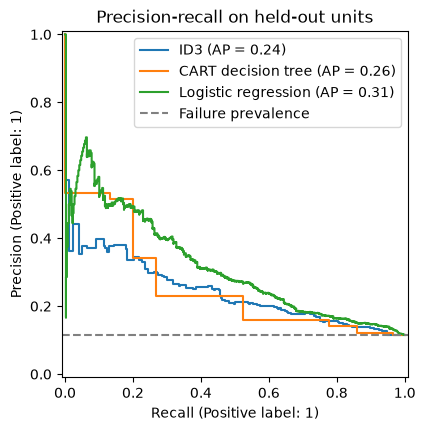

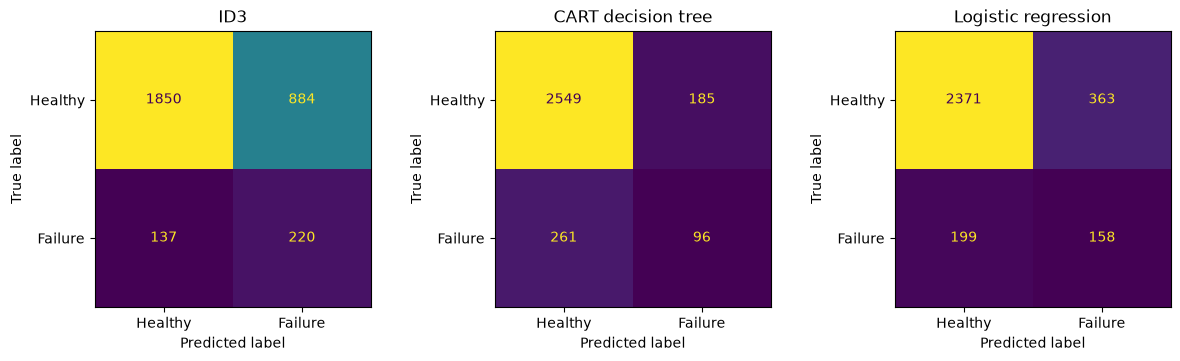

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, scores in test_scores.items():
    PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=ax)
ax.axhline(y_test.mean(), color="gray", linestyle="--", label="Failure prevalence")
ax.set_title("Precision-recall on held-out units")
ax.legend()
plt.show()

fig, axes = plt.subplots(1, len(models), figsize=(12, 3.5), layout="constrained")
for ax, (name, predictions) in zip(axes, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=[0, 1], display_labels=["Healthy", "Failure"],
        colorbar=False, ax=ax,
    )
    ax.set_title(name)
plt.show()

### Learned CART rules

Read each split from the root. The left branch satisfies the displayed condition and the right branch takes the remaining observations. Numeric thresholds are in the preprocessed feature scale. Thresholds of 0.5 on one-hot columns separate a category from its complement. Node colors show the majority class during training. The evaluation uses the development-selected threshold from the table above.

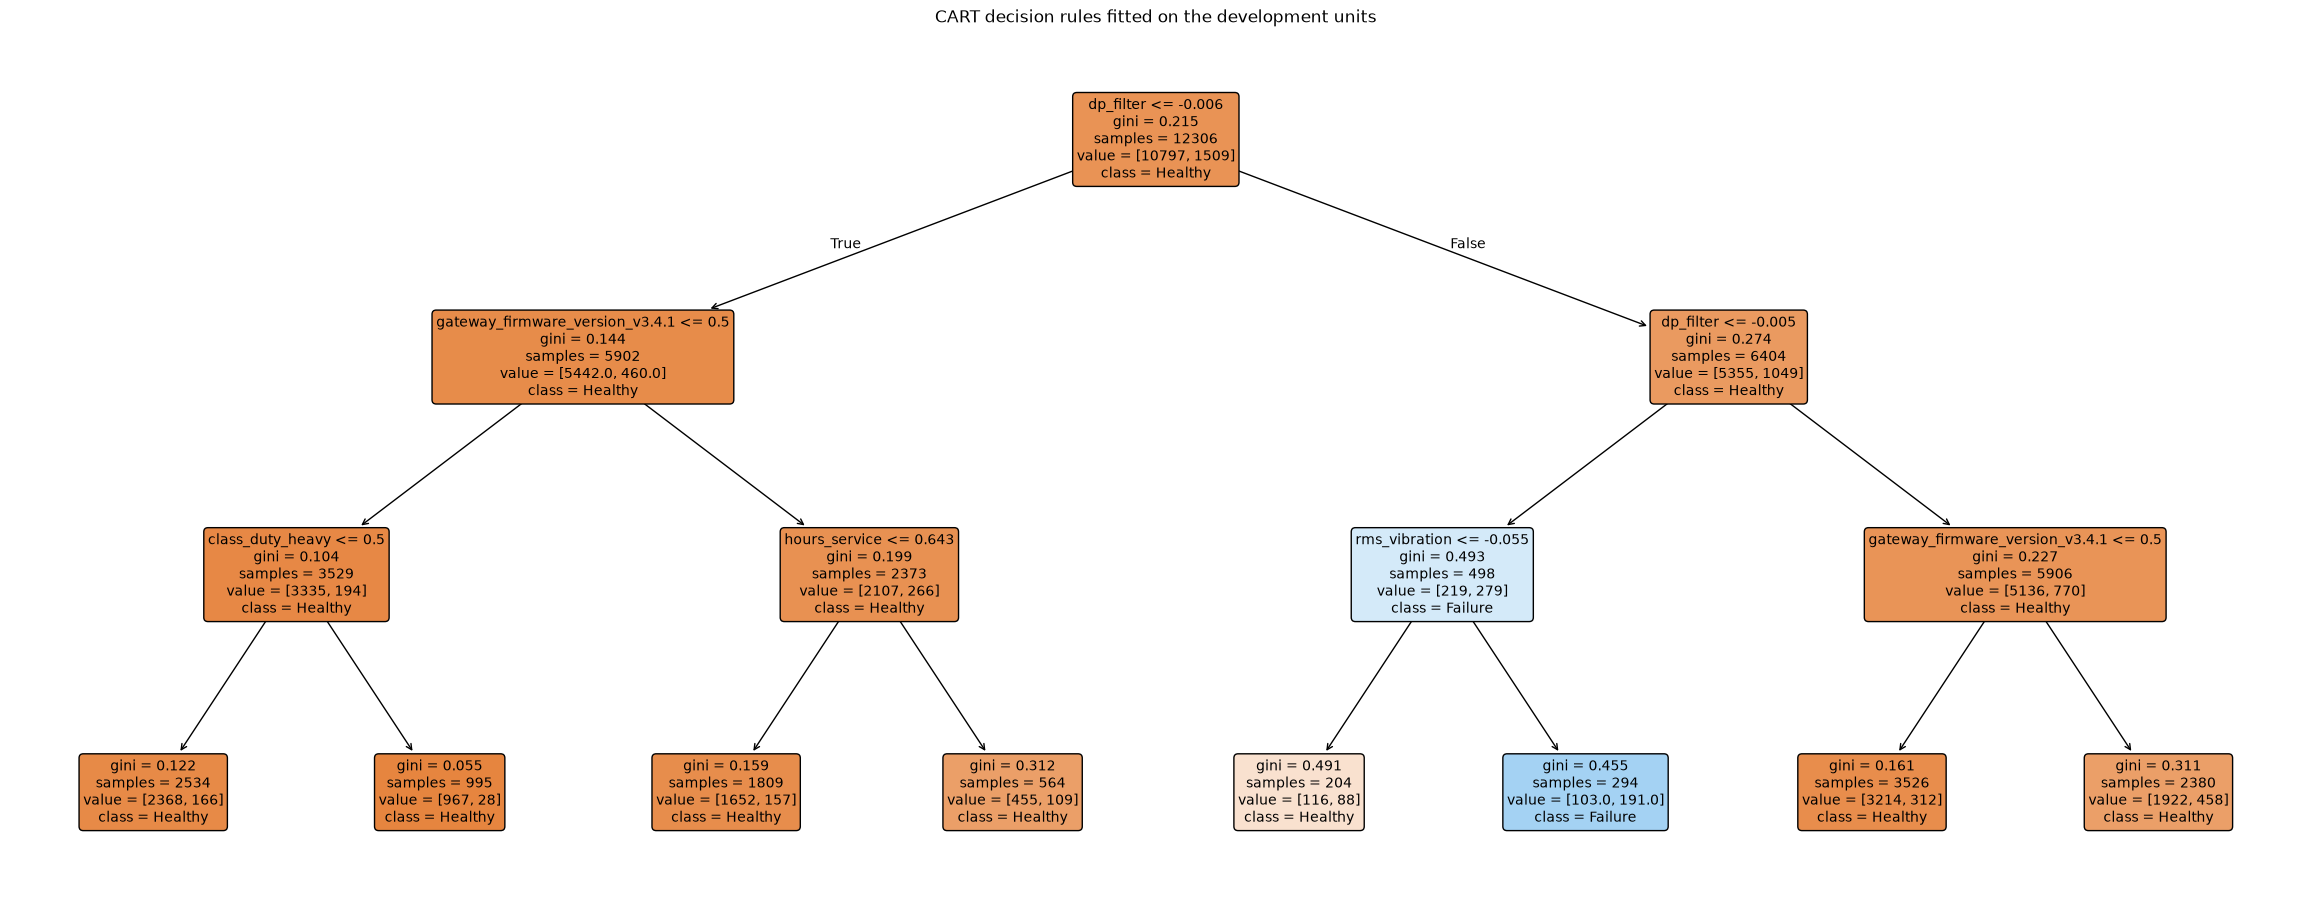

In [13]:
cart = fitted_models["CART decision tree"]
fig, ax = plt.subplots(figsize=(23, 9), layout="constrained")
plot_tree(
    cart.named_steps["classifier"],
    feature_names=cart[:-1].get_feature_names_out().tolist(),
    class_names=["Healthy", "Failure"], filled=True, rounded=True, fontsize=10, ax=ax,
)
ax.set_title("CART decision rules fitted on the development units")
plt.show()

### Results on unseen units

Logistic regression has the highest held-out AP (0.313), ROC AUC (0.731), and F1 (0.360). CART ranks second by AP (0.256), followed by ID3 (0.241). All three exceed the failure-prevalence baseline of 0.115.

At the selected thresholds, ID3 catches 220 of 357 failures (61.6% recall) and raises 884 false alarms. CART raises the fewest false alarms (185) and catches 96 failures. Logistic regression catches 158 failures with 363 false alarms. These results compare the models on new units for the observed cycle. They do not measure how far ahead a failure can be predicted.

CART uses `dp_filter` for the root split and uses it again on the right branch. That second split isolates a narrow range of preprocessed filter-pressure readings, which the next rule divides by `rms_vibration`. ID3's quantile bins give it coarser numeric boundaries, and it can use each attribute only once on a path.

## 3.3 Optimization, also known as hyperparameter tuning

The chosen algorithm is the decision tree (CART). Its splits capture interactions between sensors. All searches and scores use the five grouped folds from the evaluation protocol, so readings of one unit never appear in both the training and the validation part of a split. Preprocessing is part of each pipeline (`build_model`), so imputation, Yeo-Johnson, scaling, one-hot encoding and the variance filter are refitted on the training part of every fold. The score is average precision: it measures how well the failure probabilities rank the failures and equals the failure rate for a constant score, so the healthy majority does not dominate it as it dominates accuracy.

### 3.3.A Hyperparameter tuning

`GridSearchCV` tries 96 settings of the decision tree and scores each on the five folds. The refitted tree has accuracy ~0.74 on the training set and ~0.71 on the testing set. It reaches a mean validation AP of 0.337 and a training AP of ~0.416.

In [14]:
tree_search = GridSearchCV(
    build_model(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    {"classifier__max_depth": [3, 4, 5, 6, 8, 12],
     "classifier__min_samples_leaf": [25, 50, 100, 200],
     "classifier__criterion": ["gini", "entropy"],
     "classifier__class_weight": [None, "balanced"]},
    scoring="average_precision", 
    cv=folds, 
    n_jobs=-1, 
    return_train_score=True,
).fit(X_train, y_train)

tuned_tree = tree_search.best_estimator_

tree_params = {name.split("__")[1]: value for name, value in tree_search.best_params_.items()}
best = tree_search.best_index_

print("Best parameters:", tree_params)
print(f"Validation AP {tree_search.best_score_:.3f}, train AP {tree_search.cv_results_['mean_train_score'][best]:.3f}")

Best parameters: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 25}
Validation AP 0.337, train AP 0.416


### 3.3.B Ensembles

An ensemble combines several models so that their errors partly cancel. Two ensembles are built, both inside `build_model`:

- **Bagged tuned trees:** 100 copies of the tuned decision tree, each fitted on a random 80% of the training readings. The predictions are averaged, which reduces the variance of a single deep tree. This ensemble uses the settings found in 3.3.A.
- **Voting ensemble:** a `VotingClassifier` with soft voting, which averages the predicted failure probabilities of gradient boosting (200 trees of depth 2, learning rate 0.03, at least 50 readings per leaf; each tree corrects the errors of the previous ones) and a random forest (300 trees with at least 50 readings per leaf and class weights balanced within each bootstrap sample). Boosting reduces bias and the forest reduces variance. Shallow trees, a low learning rate and large leaves keep both members from memorising the training readings.

In [15]:
bagged_tree = build_model(BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE, **tree_params),
    n_estimators=100,
    max_samples=0.8,
    random_state=RANDOM_STATE,
))

base_models = [
    ("boosting", GradientBoostingClassifier(
        n_estimators=200, max_depth=2, learning_rate=0.03, min_samples_leaf=50, random_state=RANDOM_STATE)),
    ("forest", RandomForestClassifier(
        n_estimators=300, min_samples_leaf=50, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)),
]
ensemble_model = build_model(VotingClassifier(estimators=base_models, voting="soft", n_jobs=-1))
ensemble_model.fit(X_train, y_train)

print("Ensembled training model score:", ensemble_model.score(X_train, y_train))
print("Ensembled testing model score:", ensemble_model.score(X_test, y_test))

Ensembled training model score: 0.8972858768080612
Ensembled testing model score: 0.9052086703332255


### 3.3.C Cross-validation

`cross_validate` evaluates the tuned tree and both ensembles on the same five grouped folds, with AP as the score. Each model is cloned and its whole pipeline is refitted on the training part of every fold, and the training scores are kept for 3.3.D. Using the same folds makes the differences between models paired.

Both ensembles beat the tuned tree in all five folds, bagging by 0.061 and voting by 0.113 on average.

In [16]:
models_to_compare = {
    "Tuned decision tree": tuned_tree,
    "Bagged tuned trees": bagged_tree,
    "Voting ensemble": ensemble_model,
}

cv_results = {
    name: cross_validate(model, X_train, y_train, cv=folds, scoring="average_precision", return_train_score=True, n_jobs=-1)
    for name, model in models_to_compare.items()
}

cv_table = pd.DataFrame({name: r["test_score"] for name, r in cv_results.items()}, index=range(1, 6)).T
cv_table.columns = [f"fold {i}" for i in cv_table.columns]
cv_table["mean AP"] = cv_table.mean(axis=1)
cv_table["sd"] = cv_table.iloc[:, :5].std(axis=1)
display(cv_table.round(3))

tree_folds = cv_results["Tuned decision tree"]["test_score"]
for name in ("Bagged tuned trees", "Voting ensemble"):
    better = int((cv_results[name]["test_score"] > tree_folds).sum())
    print(f"{name}: mean difference {(cv_results[name]['test_score'] - tree_folds).mean():+.3f}")

,fold 1,fold 2,fold 3,fold 4,fold 5,mean AP,sd
Tuned decision tree,0.359,0.315,0.365,0.300,0.345,0.337,0.028
Bagged tuned trees,0.416,0.389,0.403,0.369,0.413,0.398,0.019
Voting ensemble,0.454,0.471,0.467,0.428,0.428,0.450,0.021


Bagged tuned trees: mean difference +0.061
Voting ensemble: mean difference +0.113


### 3.3.D: Overfitting check

Two comparisons are made for every model: training AP against validation AP inside cross-validation (the gap), and the cross-validated AP against the AP on the Phase 2 holdout units, which no choice used.

In [17]:
rows = {}
for name, model in models_to_compare.items():
    fitted = clone(model).fit(X_train, y_train)
    cv_train = cv_results[name]["train_score"].mean()
    cv_validation = cv_results[name]["test_score"].mean()
    rows[name] = {
        "train AP (CV)": cv_train,
        "validation AP (CV)": cv_validation,
        "gap (CV)": cv_train - cv_validation,
        "train AP (all)": average_precision_score(y_train, fitted.predict_proba(X_train)[:, 1]),
        "test AP": average_precision_score(y_test, fitted.predict_proba(X_test)[:, 1]),
    }
    
overfit_table = pd.DataFrame(rows).T
overfit_table["test minus validation"] = overfit_table["test AP"] - overfit_table["validation AP (CV)"]
display(overfit_table.round(3))

print(f"Best model by validation AP: {overfit_table["validation AP (CV)"].idxmax()}")

,train AP (CV),validation AP (CV),gap (CV),train AP (all),test AP,test minus validation
Tuned decision tree,0.416,0.337,0.079,0.399,0.298,-0.039
Bagged tuned trees,0.505,0.398,0.107,0.491,0.379,-0.019
Voting ensemble,0.538,0.450,0.088,0.537,0.467,0.017


Best model by validation AP: Voting ensemble


The best model is the voting ensemble, and it has a train-validation gap of 0.088, test AP (0.467) is 0.017 above its validation AP.

In [18]:
def boosting():
    return HistGradientBoostingClassifier(max_depth=2, learning_rate=0.05, max_iter=100, min_samples_leaf=200, l2_regularization=30, early_stopping=False, random_state=RANDOM_STATE)

def forest():
    return RandomForestClassifier(n_estimators=200, max_depth=4, min_samples_leaf=100, max_features="sqrt", class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)

regularised_models = {
    "Regularised tree": build_model(DecisionTreeClassifier(max_depth=5, min_samples_leaf=25, ccp_alpha=0.001, class_weight="balanced", random_state=RANDOM_STATE)),
    "Regularised boosting": build_model(boosting()),
    "Regularised voting ensemble": build_model(VotingClassifier([("boosting", boosting()), ("forest", forest())], voting="soft")),
}

regularised_cv = {
    name: cross_validate(model, X_train, y_train, cv=folds, scoring="average_precision", return_train_score=True, n_jobs=-1)
    for name, model in regularised_models.items()
}

rows = {}
for name, model in regularised_models.items():
    fitted = clone(model).fit(X_train, y_train)
    cv_train = regularised_cv[name]["train_score"].mean()
    cv_validation = regularised_cv[name]["test_score"].mean()
    rows[name] = {
        "train AP (CV)": cv_train,
        "validation AP (CV)": cv_validation,
        "gap (CV)": cv_train - cv_validation,
        "train AP (all)": average_precision_score(y_train, fitted.predict_proba(X_train)[:, 1]),
        "test AP": average_precision_score(y_test, fitted.predict_proba(X_test)[:, 1]),
    }

regularised_table = pd.DataFrame(rows).T
regularised_table["test minus validation"] = regularised_table["test AP"] - regularised_table["validation AP (CV)"]
display(regularised_table.round(3))

print(f"Best model by validation AP: {regularised_table["validation AP (CV)"].idxmax()}")

,train AP (CV),validation AP (CV),gap (CV),train AP (all),test AP,test minus validation
Regularised tree,0.339,0.313,0.026,0.342,0.287,-0.026
Regularised boosting,0.492,0.456,0.036,0.495,0.472,0.017
Regularised voting ensemble,0.472,0.434,0.038,0.477,0.451,0.017


Best model by validation AP: Regularised boosting


The first table shows train-validation gaps of 0.079 (tuned tree), 0.107 (bagged trees) and 0.088 (voting ensemble), all above the limit of 0.05. The models were then limited so that they cannot fit the training rows closely.

The tree was pruned (`ccp_alpha` 0.001) and limited to depth 5. Boosting now is `HistGradientBoostingClassifier` with trees of depth 2, learning rate 0.05, 100 iterations, leaves of at least 200 readings and an L2 penalty of 30. The Random forest in the voting ensemble has depth 4 and leaves of at least 100 readings.

All three regularised models have a gap below 0.05. The gap of the voting ensemble falls by more than half (0.088 to 0.038) and its validation AP falls by only 0.016. Boosting alone has the highest validation AP of all models (0.456, against 0.450 for the earlier voting ensemble) and the smallest gap among the ensembles.

**Evidence of no overfitting**

The train-validation gap is 0.026 for the tree, 0.036 for boosting and 0.038 for the voting ensemble. All are below 0.05. The test AP is 0.017 above the validation AP for boosting and for the voting ensemble, and 0.026 below it for the tree. The holdout units took no part in training or tuning, so the validation estimate holds on new units and does not fall below it for the ensembles. The training AP of the model fitted on all readings (0.495 for boosting) is equal to the training AP inside cross-validation (0.492), so the final model memorises its training data no more than the cross-validated models do.

**Evidence of no underfitting**

A model with no skill has AP equal to the failure rate (0.123 in training, 0.115 in the holdout). Boosting reaches a validation AP of 0.456 and a test AP of 0.472, about four times the holdout failure rate. The training AP of boosting inside cross-validation is 0.492.

The regularised boosting model is the best model to use. It has the highest validation AP (0.456), a gap of 0.036 below the limit, and a test AP (0.472) above its validation AP.

## 3.4 Evaluating the impact of your chosen strategies on classification

### 3.4.A Data preprocessing strategies for the given dataset

The dataset contains sensor measurements, machine metadata and missing or invalid values.

The following strategies were evaluated:

- Exact duplicates were removed before modeling to prevent repeated observations from biasing training.
- Infinite sensor values, oil temperature of -999, humidity outside 0–100%, negative service hours and invalid longitude values were converted to missing values.
- Mean and median imputation changed AP by less than one fold standard deviation. Median was selected because it is less sensitive to skewed sensor distributions and extreme values.
- The variance filter did not change AP and removed 94 of 220 one-hot encoded columns, reducing the feature space without a measurable loss of performance.

### 3.4.B: Data transformation

Different transformations were applied according to the nature of the input attributes and the requirements of the algorithms.

- Yeo-Johnson on `motor_current`, `dp_filter`, `rms_vibration`, `hours_service`. It reduces skewness and makes numerical distributions more symmetric. It was selected because it can transform both positive and negative numerical values and is suitable for skewed sensor measurements.
- `StandardScaler` standardizes numerical features to comparable scales.
- One-hot encoding converts categories into numerical columns that `scikit-learn` models can use.
- Quantile discretization divides numerical measurements into four quantile-based bins so that ID3 can use categorical splits.
- Variance filtering removes features with variance below 0.01.

Tree-based algorithms use feature thresholds to create splits. They are generally less sensitive to monotonic transformations and do not require standard scaling in the same way as linear models.

### 3.4.C: Feature selection, metrics, algorithms, hyper. tuning, ensemble learning

The ten attributes selected in Phase 2 increased logistic regression AP by 0.010 (to 0.327 in all five folds) but decreased boosting AP by 0.002. Removing only `manufacturer`, `gateway_vendor` and `id_depot` increased logistic regression AP by 0.006 and did not change boosting AP. Feature selection therefore provided a small benefit to the linear model but did not improve the tree-based model. Consequently, all 17 candidate attributes are retained for the final model.

| Model | Validation AP | Train-validation gap |
|---|---:|---:|
| ID3, 5 levels | 0.195 | 0.078 |
| CART, depth 3 | 0.263 | 0.014 |
| Logistic regression, default | 0.311 | 0.044 |
| Logistic regression, tuned | 0.317 | Not computed |
| Tuned decision tree | 0.337 | 0.079 |
| Bagged tuned trees | 0.398 | 0.107 |
| Voting ensemble | 0.450 | 0.088 |
| Regularised tree | 0.313 | 0.026 |
| Regularised Voting ensemble | 0.434 | 0.038 |
| Regularised boosting | **0.456** | **0.036** |

Hyperparameter tuning improved the decision tree from 0.263 to 0.337 AP. Bagging improved the tuned tree by 0.061 AP, while the original Voting ensemble improved it by 0.113 AP. However, the original ensembles had larger training-validation gaps, so regularisation was investigated.

Restricting model complexity reduced the gap of the original Voting ensemble from 0.088 to 0.038. Its validation AP decreased from 0.450 to 0.434. The regularised tree also had a smaller gap of 0.026, but its AP decreased to 0.313. Regularised boosting achieved a validation AP of 0.456 and a training-validation gap of 0.036. It therefore offered the best balance between classification quality and generalization.

The development data contains approximately 87.7% healthy observations and 12.3% failure observations. A classifier that always predicts healthy would achieve approximately 87.7% accuracy but zero failure recall. Average precision is used as the primary model-selection metric because it evaluates how well the model ranks failures while considering precision and recall. A constant prediction has AP equal to the failure prevalence (approximately 0.123 in the development data).


### 3.4.D: Which model is your best model for deployment?

The deployment model is selected based on two requirements:

1. High mean validation average precision.
2. A mean training-validation AP gap below 0.05 (<5%)

| Model | Training AP (CV) | Validation AP (CV) | Gap | Test AP |
|---|---:|---:|---:|---:|
| Regularised tree | 0.339 | 0.313 | 0.026 | 0.287 |
| Regularised boosting | 0.492 | **0.456** | 0.036 | **0.472** |
| Regularised Voting | 0.472 | 0.434 | 0.038 | 0.451 |

Regularised boosting was selected because it achieved the highest validation AP among the regularised models while keeping the mean training-validation gap below 0.05. Its five validation-fold AP scores were:

| Fold | Validation AP | Train-validation gap |
|---|---:|---:|
| 1 | 0.453 | 0.048 |
| 2 | 0.468 | 0.028 |
| 3 | 0.471 | 0.009 |
| 4 | 0.416 | 0.075 |
| 5 | 0.471 | 0.020 |
| Mean AP | **0.456** | **0.036** |

The validation AP standard deviation is 0.023, indicating reasonably consistent performance across folds. The gap is below 0.05 in four out of five folds, although fold 4 exceeds this limit. Therefore, the model has a small average gap but is not perfectly consistent in every fold.

The selected model achieves:

- Mean validation AP: 0.456.
- Mean training AP: 0.492.
- Training-validation gap: 0.036.
- Test AP on unseen units: 0.472.

The test AP is 0.017 higher than the mean validation AP. This suggests that the model maintains its ranking performance on previously unseen machines. A constant score model has AP equal to the failure prevalence, approximately 0.123 in the development data and 0.115 in the holdout set. The selected model achieves validation AP of 0.456 and test AP of 0.472, considerably above these baselines. Its training AP of 0.492 also demonstrates that it has learned useful patterns. Therefore, regularised HistGradientBoostingClassifier is selected as the best deployment candidate. It provides the highest validation and test AP among the evaluated regularised models while maintaining a relatively small average generalization gap.


### 3.4.E: What is the data pipeline for building that model from your dataset in production?

In [22]:
import numpy as np
import pandas as pd
from pathlib import Path

COLUMN_NAMES = {
    "idUnit": "id_unit",
    "idDepot": "id_depot",
    "gatewayId": "gateway_id",
    "Ipv4": "ipv4",
    "dbmSignal": "dbm_signal",
    "Technician": "technician",
    "motorCurrent": "motor_current",
    "dpFilter": "dp_filter",
    "oilTemperature": "oil_temperature",
    "pressureReservoir": "pressure_reservoir",
    "pressureOil": "pressure_oil",
    "humidityIntake": "humidity_intake",
    "classDuty": "class_duty",
    "Manufacturer": "manufacturer",
    "hoursService": "hours_service",
}

DATE_COLUMNS = {
    "gateways": "date_install",
    "readings": "ts_cycle",
    "units": "last_overhaul",
}

SENSOR_COLUMNS = [
    "motor_current",
    "dp_filter",
    "oil_temperature",
    "pressure_reservoir",
    "pressure_oil",
    "rms_vibration",
    "flowmeter",
    "humidity_intake",
    "current_aux",
]


def prepare_raw_data(gateways_df, readings_df, units_df, require_target=False):
    tables = {"gateways": gateways_df, "readings": readings_df, "units": units_df}
    normalized = {}

    # 1. Normalize columns, IDs, strings and dates.
    for name, table in tables.items():
        frame = table.drop_duplicates().copy()
        frame = frame.rename(columns=COLUMN_NAMES)

        for column in frame.select_dtypes(include=["object", "string"]).columns:
            frame[column] = (frame[column].astype("string").str.strip().replace("", pd.NA))

        for column in [c for c in ["id_unit", "id_depot"]if c in frame]:
            key_text = frame[column].astype("string")

            if name == "readings" and column == "id_unit":
                key_text = key_text.str.replace(r"^U", "", regex=True)

            numeric_id = pd.to_numeric(key_text, errors="coerce")

            valid_id = numeric_id.notna() & np.isfinite(numeric_id) & numeric_id.ge(0) & numeric_id.mod(1).eq(0)

            frame[column] = numeric_id.where(valid_id).astype("Int64")

        frame[DATE_COLUMNS[name]] = pd.to_datetime(frame[DATE_COLUMNS[name]],format="mixed",errors="coerce")

        if name == "units":
            frame["class_duty"] = (frame["class_duty"].str.lower().replace({
                "h": "heavy",
                "l": "light",
                "n": "normal"})
            )

        normalized[name] = frame.drop_duplicates().copy()

    gateways_clean = normalized["gateways"]
    readings_clean = normalized["readings"]
    units_clean = normalized["units"]

    # 2. Handle invalid sensor measurements
    for column in SENSOR_COLUMNS:
        values = readings_clean[column]

        invalid = (values.notna() & ~np.isfinite(values))

        if column == "oil_temperature":
            invalid |= values.eq(-999)

        if column == "humidity_intake":
            invalid |= (values.notna() & ~values.between(0, 100))

        readings_clean.loc[invalid, column] = np.nan

    # 3. Handle invalid metadata measurements
    
    invalid_hours = (
        units_clean["hours_service"].lt(0) | (units_clean["hours_service"].notna() & ~np.isfinite(units_clean["hours_service"]))
    )

    units_clean.loc[invalid_hours, "hours_service"] = np.nan
    invalid_longitude = gateways_clean["lon"].notna() & ~gateways_clean["lon"].between(-180, 180)
    gateways_clean.loc[invalid_longitude, "lon"] = np.nan

    # 4. Validate readings
    
    valid_readings = readings_clean["id_unit"].notna() & readings_clean["ts_cycle"].notna()

    if require_target:

        if "failure" not in readings_clean.columns:
            raise ValueError("Training data must contain failure target")

        conflicting_labels = (readings_clean.groupby(["id_unit", "ts_cycle"], dropna=False)["failure"].transform("nunique").gt(1))
        valid_readings &= readings_clean["failure"].isin([0, 1]) & ~conflicting_labels

    readings_for_merge = readings_clean.loc[valid_readings].copy()

    # 5. Join readings with unit metadata
    
    integrated_df = readings_for_merge.merge(units_clean, on="id_unit", how="left", validate="many_to_one", indicator="unit_match")

    cleaned_df = integrated_df.loc[integrated_df["unit_match"].eq("both")].copy()
    cleaned_df = cleaned_df.drop(columns="unit_match")

    # 6. Join gateway metadata
    
    linked_gateways = gateways_clean.loc[gateways_clean["id_unit"].notna()].copy()

    gateway_metadata = linked_gateways.rename(columns={c: f"gateway_{c}"for c in linked_gateways if c != "id_unit"})

    cleaned_df = cleaned_df.merge(gateway_metadata, on="id_unit", how="left", validate="many_to_one")

    return cleaned_df.reset_index(drop=True)

def load_raw_csvs(dataset_dir):
    dataset_dir = Path(dataset_dir)

    gateways = pd.read_csv(dataset_dir / "gateways.csv", sep=";")
    readings = pd.read_csv(dataset_dir / "readings.csv", sep="\t")
    units = pd.read_csv(dataset_dir / "units.csv")

    return gateways, readings, units

def prepare_production_csvs(dataset_dir):
    gateways, readings, units = load_raw_csvs(dataset_dir)

    return prepare_raw_data(gateways, readings, units, require_target=False)

def predict_from_raw_csvs(dataset_dir, artifact_directory):
    raw_data = prepare_production_csvs(dataset_dir)

    predictions = predict_new_observations(raw_data,artifact_directory)

    return predictions

In [23]:
import sys
import importlib
from pathlib import Path

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "src"
    else Path.cwd()
)

PHASE3_DIR = PROJECT_ROOT / "tmp" / "phase3"
PHASE3_DIR.mkdir(parents=True, exist_ok=True)

module_code = '''
def add_interval(df, later, earlier, name):
    df = df.copy()
    days = ((df[later] - df[earlier]).dt.total_seconds() / 86400)
    df[name] = days.where(days >= 0)

    return df

def to_text(df):
    return (df.astype("string").fillna("missing").astype(str))

def append_name(transformer, names):
    new = transformer.kw_args["name"]
    return (list(names) if new in names else [*names, new])
'''

module_path = PHASE3_DIR / "production_features.py"
module_path.write_text(module_code.strip() + "\n", encoding="utf-8")

phase3_path = str(PHASE3_DIR.resolve())

if phase3_path not in sys.path:
    sys.path.insert(0, phase3_path)

sys.modules.pop("production_features", None)
importlib.invalidate_caches()

from production_features import (add_interval,to_text,append_name)

In [24]:
import json
import platform
from datetime import datetime, timezone
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    precision_recall_curve,
)
from sklearn.model_selection import cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    PowerTransformer,
    StandardScaler,
)

# 1. Reproducible preprocessing

from production_features import (
    add_interval,
    to_text,
    append_name
)

# 2. Define the model input schema

numeric = ["motor_current", "dp_filter", "oil_temperature", "pressure_reservoir", "pressure_oil", "rms_vibration", "flowmeter", "humidity_intake", "current_aux", "hours_service", "gateway_dbm_signal", "days_since_overhaul"]
categorical = ["class_duty", "manufacturer", "gateway_firmware_version", "gateway_vendor", "id_depot"]
skewed = ["motor_current", "dp_filter", "rms_vibration", "hours_service"]
interval = ("ts_cycle", "last_overhaul", "days_since_overhaul")

input_columns = ([c for c in numeric if c != interval[2]] + categorical + list(interval[:2]))

RANDOM_STATE = 1234

# 3. Build the complete pipeline

def build_pipeline(numeric, categorical, skewed=(), interval=None, random_state=RANDOM_STATE):
    skewed = [c for c in skewed if c in numeric]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("power", ColumnTransformer([("yeo_johnson", PowerTransformer(standardize=False), skewed)], remainder="passthrough", verbose_feature_names_out=False)),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("text", FunctionTransformer(to_text, feature_names_out="one-to-one")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    
    branches = []
    if numeric:
        branches.append(("numeric", numeric_pipeline, numeric))
    if categorical:
        branches.append(("categorical", categorical_pipeline, categorical))

    steps = []
    if interval is not None:
        later, earlier, name = interval
        steps.append(("interval", FunctionTransformer(add_interval, kw_args={"later": later, "earlier": earlier, "name": name}, feature_names_out=append_name)))
    
    steps += [
        ("columns", ColumnTransformer(branches, verbose_feature_names_out=False)),
        ("variance", VarianceThreshold(threshold=0.01)),
        ("classifier", HistGradientBoostingClassifier(max_depth=2, learning_rate=0.05, max_iter=100, min_samples_leaf=200, l2_regularization=30, early_stopping=False, random_state=random_state)),
    ]
    
    return Pipeline(steps).set_output(transform="pandas")

# 4. Create the final model

model = build_pipeline( numeric=numeric, categorical=categorical, skewed=skewed, interval=interval, random_state=RANDOM_STATE)

# 5. Evaluate with the same five grouped folds

oof_probabilities = cross_val_predict(model, X_train[input_columns], y_train, cv=folds, method="predict_proba", n_jobs=-1)[:, 1]

# Cross-validation scores and training scores.
cv_results_final = cross_validate(model, X_train[input_columns], y_train, cv=folds, scoring="average_precision", return_train_score=True, n_jobs=-1)

cv_ap = cv_results_final["test_score"]
cv_train_ap = cv_results_final["train_score"]

validation_ap_mean = float(cv_ap.mean())
validation_ap_sd = float(cv_ap.std(ddof=1))

train_validation_gap = float(cv_train_ap.mean() - cv_ap.mean())

# 6. Select the classification threshold

precision, recall, thresholds = precision_recall_curve(y_train, oof_probabilities,)

f1_values = 2 * precision * recall / (precision + recall + 1e-12)

threshold = float(thresholds[np.argmax(f1_values[:-1])])

# 7. Fit the final model on all development observations

model.fit(X_train[input_columns], y_train)

# 8. Evaluate once on completely unseen test units

test_probabilities = model.predict_proba(X_test[input_columns])[:, 1]

test_predictions = (test_probabilities >= threshold).astype(int)
test_ap = average_precision_score(y_test, test_probabilities)

test_accuracy = accuracy_score(y_test, test_predictions)
test_precision = precision_score(y_test, test_predictions, zero_division=0)

test_recall = recall_score(y_test, test_predictions, zero_division=0)
test_f1 = f1_score(y_test, test_predictions, zero_division=0)
test_balanced_accuracy = balanced_accuracy_score(y_test, test_predictions)
test_confusion_matrix = confusion_matrix(y_test, test_predictions, labels=[0, 1])

# 9. Collect metadata

metadata = {
    "raw_data_preparation": {
        "source_files": [
            "gateways.csv",
            "readings.csv",
            "units.csv"
        ],

        "separators": {
            "gateways.csv": ";",
            "readings.csv": "\t",
            "units.csv": ","
        },

        "duplicate_removal": True,
        "identifier_normalization": True,

        "date_columns": [
            "date_install",
            "ts_cycle",
            "last_overhaul"
        ],

        "invalid_value_rules": {
            "non_finite_sensor_values": "missing",
            "oil_temperature_minus_999": "missing",
            "humidity_outside_0_100": "missing",
            "negative_hours_service": "missing",
            "invalid_longitude": "missing"
        },

        "joins": {
            "readings_to_units": "id_unit",
            "readings_to_gateways": "id_unit",
            "relationship": "many_to_one"
        },

        "training_target_validation": [
            "valid failure labels",
            "remove contradictory cycle labels"
        ],

        "inference_target_required": False
    },

    "model": "Regularised HistGradientBoostingClassifier",

    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "target": "failure",

    "class_mapping": {
        "0": "healthy",
        "1": "failure"
    },

    "random_state": RANDOM_STATE,

    "input_columns": input_columns,
    "numeric_columns": numeric,
    "categorical_columns": categorical,
    "skewed_columns": skewed,

    "interval_feature": {
        "later": interval[0],
        "earlier": interval[1],
        "output": interval[2],
        "unit": "days"
    },

    "output_features": (
        model[:-1].get_feature_names_out().tolist()
    ),

    "preprocessing": {
        "imputation": "median",
        "numerical_transformation": "Yeo-Johnson",
        "scaling": "StandardScaler",
        "categorical_encoding": "OneHotEncoder",
        "variance_threshold": 0.01
    },

    "hyperparameters": (
        model.named_steps["classifier"].get_params(deep=False)
    ),

    "threshold": threshold,

    "threshold_rule": (
        "Maximum F1 on out-of-fold development predictions"
    ),

    "validation": {
        "folds": 5,
        "scoring": "average_precision",
        "fold_ap": cv_ap.tolist(),
        "mean_ap": validation_ap_mean,
        "standard_deviation": validation_ap_sd,
        "mean_train_ap": float(cv_train_ap.mean()),
        "mean_train_validation_gap": train_validation_gap
    },

    "test": {
        "average_precision": float(test_ap),
        "accuracy": float(test_accuracy),
        "precision": float(test_precision),
        "recall": float(test_recall),
        "f1": float(test_f1),
        "balanced_accuracy": float(test_balanced_accuracy),
        "confusion_matrix": test_confusion_matrix.tolist()
    },

    "data": {
        "training_rows": int(len(X_train)),
        "training_units": int(groups.nunique()),
        "test_rows": int(len(X_test)),
        "test_units": int(test_df["id_unit"].nunique()),
        "failure_prevalence": float(y_train.mean()),
        "test_failure_prevalence": float(y_test.mean())
    },

    "libraries": {
        "python": platform.python_version(),
        "scikit_learn": sklearn.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__
    }
}

# 10. Save the fitted model and its metadata

artifact_directory = PHASE3_DIR
artifact_directory.mkdir(parents=True, exist_ok=True)

joblib.dump(model, artifact_directory / "failure_model.joblib")

with open(artifact_directory / "metadata.json", "w", encoding="utf-8") as handle:
    json.dump(metadata, handle, indent=4, default=str)

print("\nSaved production files:")
print(artifact_directory / "failure_model.joblib")
print(artifact_directory / "metadata.json")

# 11. Print final results

print("Final model")

print(f"Classification threshold: {threshold:.3f}")
print(f"Validation AP: " f"{validation_ap_mean:.3f} " f"+/- {validation_ap_sd:.3f}")
print(f"Training-validation gap: " f"{train_validation_gap:.3f}")
print(f"Test AP: {test_ap:.3f}")
print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test precision: {test_precision:.3f}")
print(f"Test recall: {test_recall:.3f}")
print(f"Test F1: {test_f1:.3f}")

print("\nConfusion matrix:")
print(test_confusion_matrix)

# 12. Reusable prediction function for new observations

def predict_new_observations(prepared_data, artifact_directory):
    artifact_directory = Path(artifact_directory).resolve()

    if str(artifact_directory) not in sys.path:
        sys.path.insert(0, str(artifact_directory))

    fitted_model = joblib.load(artifact_directory / "failure_model.joblib")

    with open(artifact_directory / "metadata.json", encoding="utf-8") as handle:
        saved_metadata = json.load(handle)

    required_columns = saved_metadata["input_columns"]

    missing_columns = (set(required_columns) - set(prepared_data.columns))

    if missing_columns:
        raise ValueError(f"Missing required input columns: {sorted(missing_columns)}")

    new_X = prepared_data[required_columns].copy()
    probabilities = fitted_model.predict_proba(new_X)[:, 1]
    predictions = (probabilities >= saved_metadata["threshold"]).astype(int)

    return pd.DataFrame({"failure_probability": probabilities, "predicted_failure": predictions},index=prepared_data.index)


Saved production files:
D:\PycharmProjects\IAU_Kysil_Petrishka\tmp\phase3\failure_model.joblib
D:\PycharmProjects\IAU_Kysil_Petrishka\tmp\phase3\metadata.json
Final model
Classification threshold: 0.199
Validation AP: 0.456 +/- 0.023
Training-validation gap: 0.036
Test AP: 0.472
Test accuracy: 0.873
Test precision: 0.450
Test recall: 0.437
Test F1: 0.443

Confusion matrix:
[[2543  191]
 [ 201  156]]


Before building the final deployment pipeline, we create a separate Python module called `production_features.py`. This module contains the custom preprocessing functions used by the machine-learning pipeline. The code creates the file using Python's `Path` and `write_text()` methods. It saves the file in the current working directory of the Jupyter Notebook. The exact location is displayed using `module_path.resolve()`.

The module contains three functions:

- `add_interval()` calculates the number of days between the measurement cycle date and the last overhaul date. It creates the `days_since_overhaul` feature and treats negative intervals as missing values.
- `to_text()` converts categorical attributes into strings and replaces missing categorical values with the `"missing"` category before one-hot encoding.
- `append_name()`preserves existing feature names and adds the name of the engineered feature when required by the scikit-learn pipeline.

These functions are used by `FunctionTransformer` in our preprocessing pipeline. Separating them from the notebook makes the code easier to maintain and allows the same functions to be imported into another Python application. The module is imported into the main notebook using:

```python
from production_features import (
    add_interval,
    to_text,
    append_name
)
```

This is also important when saving and loading the fitted pipeline with Joblib. The saved model references these custom functions, so the module must remain available in the Python environment where the model is loaded. `production_features.py` file contains only the Python source code for the three preprocessing functions. It does not contain the trained classifier, dataset or model metadata. Those are saved separately as `failure_model.joblib` and `metadata.json`.

After importing these functions, we rebuild and fit the final pipeline and save the updated model. This ensures that the serialized model uses the importable functions from the production module rather than relying on notebook-local definitions.

After training, the final model is saved as a `.joblib` file, while its metadata is stored separately in a JSON file. These two files allow the trained model to be reused for predictions without repeating the training process. `failure_model.joblib` contains the fitted machine learning pipeline, including the preprocessing transformations, categorical encoding, feature selection and trained classifier. `metadata.json` stores information about the model and its development, including the target variable, required input columns, preprocessing configuration, model hyperparameters, classification threshold, validation results, test metrics. The `.joblib` file is responsible for making predictions, while the metadata file documents the model and its expected configuration. 